# Data exploration & setup

### Imports

In [1]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:95% !important; }</style>"))

In [2]:
#import stream as st

from pathlib import Path as path

from io import StringIO
import itertools as it

from scipy.io import mmread
from typing import Callable, Dict
import pandas as pd


In [3]:
import scipy

In [4]:
scipy.__version__

'1.17.1'

In [5]:
import scanpy as sc
import anndata as ad

In [6]:
from upsetplot import generate_counts
from upsetplot import plot
from matplotlib import pyplot
from upsetplot import UpSet

In [7]:
from stream_qc_minimal import cal_qc, plot_qc

In [8]:
import scib

In [9]:
import itertools as it
from markers import (
    positive_markers, # function to generate a configuration dictionnary from a set of marker genes
    states_and_markers, # Dictionnary containing phenotypes and their marker genes
)

In [10]:
from data_prep import *

In [11]:
#import lamindb as ln

# Suppress verbose logging from Scanpy
sc.settings.verbosity = 0

# Set figure parameters for clean, minimal plots
sc.settings.set_figure_params(dpi=80, facecolor="white", frameon=False)

#assert ln.setup.settings.instance.slug == "theislab/sc-best-practices"

#ln.track()

In [12]:
datasetsIds = it.product(("young_", "old_"), ("A", "B"))
datasetsIds = list(map(lambda x: "".join(x), datasetsIds))
datasetsIds = ["GSM444387" + str((idx+5)) + "_" + name + "_" for idx, name in enumerate(datasetsIds)]
datasetsIds

['GSM4443875_young_A_',
 'GSM4443876_young_B_',
 'GSM4443877_old_A_',
 'GSM4443878_old_B_']

## Helper functions

In [13]:
def createExperimentDataFrame(experiment_id):
    suffixes = ['matrix.mtx.gz', 'genes.tsv.gz', 'barcodes.tsv.gz']
    files = {s: f"{experiment_id}{s}" for s in suffixes}  
    m = mmread(files['matrix.mtx.gz'])
    m = m.toarray()
    df = pd.read_csv(files['genes.tsv.gz'], sep='\t', names=['id', 'gene'])
    a= df['gene'].to_list()
    barcodes = pd.read_csv(files['barcodes.tsv.gz'], sep='\t', header=None)
    b = list(barcodes.values.flatten())
    df = pd.DataFrame(m, index=a, columns=b)
    
    return df

In [14]:
def createMergedDataset(file_names, datasets):
    # 2. Łączymy obiekty
    # label='batch' utworzy nową kolumnę w .obs o nazwie 'batch'
    # keys=['A', 'B'] przypisze wartości do tej kolumny
    # index_unique='_' doda sufiks do barcodów (np. AAAC...-1_A), żeby uniknąć duplikatów
    '''adata = ad.concat(
        {batch: dataset for (batch, dataset) in zip(file_names, datasets)}, 
        label="batch", 
        index_unique="_",
        axis = 'var'
    )'''
        

    # Example Fix
    combined = ad.concat(
        datasets,
        #keys=file_names,
        #label='batch_id',  # Adds a column to .obs
        join='inner',      # Keep all genes
        index_unique='_',
        merge="same"
    )
    return combined
    #return adata

In [15]:
def common_preprocessing(adata_original):
    # From the article
    adata = adata_original.copy()
    # 1. Filtrowanie komórek (min 200 genów)
    #sc.pp.filter_cells(adata, min_genes=200)
    
    # 2. Filtrowanie genów (min 3 komórki)
    #sc.pp.filter_genes(adata, min_cells=3)

    #print(adata.var_names)
    
    # 3. Usuwanie genów mitochondrialnych
    # Najpierw identyfikujemy geny MT (zaczynające się od MT- lub mt-)
    adata.var['mt'] = adata.var_names.str.startswith('MT-') # lub 'mt-' dla myszy
    # Następnie filtrujemy obiekt, zostawiając tylko te, które NIE są mt
    adata = adata[:, ~adata.var['mt']].copy()
    
    # 4. Normalizacja (library size)
    # target_sum=None automatycznie skaluje do średniej liczby zliczeń na komórkę

    return adata

In [16]:


# Definicje poszczególnych "strategii"
def hvg_scanpy(adata_original, method) -> list:
    # Implementacja specyficzna dla Seurat VST
    adata = adata_original.copy()
    common_preprocessing(adata)
    if method not in [ "pearson_residuals", "seurat_v3", "seurat_v3_paper" ]:
        # 5. Logarytmowanie
        sc.pp.normalize_total(adata, target_sum=1e4)
        sc.pp.log1p(adata)
        genes = sc.pp.highly_variable_genes(
        adata, 
        flavor=method, 
        batch_key="batch",
        inplace=False# Tutaj rozwiązujesz problem batch effect
    )
    elif method == "pearson_residuals":
        genes = sc.experimental.pp.highly_variable_genes(
        adata, 
        flavor=method,
        n_top_genes = 2000,
        batch_key="batch", # Tutaj rozwiązujesz problem batch effect
        inplace=False
    )

    else:
        print("HERE")
        print(method)
        genes = sc.pp.highly_variable_genes(
        adata, 
        flavor=method,
        n_top_genes = 2000,
        batch_key="batch", # Tutaj rozwiązujesz problem batch effect,
        inplace=False
    )
        print(genes)
        
    return genes

def hvg_scanpy_experimental(data: pd.DataFrame, n_genes: int) -> list:
    # Implementacja specyficzna dla Scanpy
    return ["gene_c", "gene_d"]




In [17]:
# Rejestr metod
HVG_METHODS: Dict[str, Callable] = {
    "seurat": hvg_scanpy,
    #"scanpy": hvg_scanpy_dispersion,
    'cell_ranger': hvg_scanpy, 
    'seurat_v3':hvg_scanpy, 
    'seurat_v3_paper':hvg_scanpy,
    "pearson_residuals":hvg_scanpy,
    "consensus": lambda data, n: list(set(hvg_seurat_vst(data, n)) & set(hvg_scanpy_dispersion(data, n)))
}


In [18]:
# Główna funkcja pipeline'u
def select_hvg(adata, method: str = "seurat", **kwargs):
    if method not in HVG_METHODS:
        raise ValueError(f"Metoda {method} nie jest wspierana. Wybierz z: {list(HVG_METHODS.keys())}")
    

    
    # Wywołanie bez żadnych instrukcji warunkowych
    return hvg_scanpy(adata, method)

In [19]:
def evaluate_hvg_selection(adata):
    hvg_results = []
    for method in {method for method in HVG_METHODS if method != 'consensus'}:
        hvg = hvg_scanpy(adata, method=method)
        hvg.rename(columns={'highly_variable':method})
        hvg = hvg[method]
        hvg_results.append(hvg)
    

### Data download and unpacking

In [9]:
!test -f 'GSE147729_RAW.tar' || \
    wget -O 'GSE147729_RAW.tar' 'https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE147729&format=file' && \
    echo "Import data and Select observarions whose ID starts with Lane1_"

Import data and Select observarions whose ID starts with Lane1_


In [10]:
!test -f 'GSM4443875_young_A_barcodes.tsv.gz' || \
    tar -xvf 'GSE147729_RAW.tar'

### Data loading

In [21]:
%%time
datasets = []
for idx in datasetsIds:
    datasets.append(createExperimentDataFrame(idx))

CPU times: user 5.02 s, sys: 365 ms, total: 5.38 s
Wall time: 3.01 s


In [78]:
result = pd.concat((young_A_df, young_B_df))

In [79]:
result.shape, young_A_df.shape, young_B_df.shape

((57384, 7749), (28692, 5431), (28692, 2337))

In [25]:
result = df

In [26]:
result.fillna(0, inplace=True)

In [27]:
result = result.apply(pd.to_numeric, downcast='integer')

In [82]:
mask = result.isna()

In [88]:
young_A_df.index

Index(['Xkr4', 'Gm1992', 'Gm37381', 'Rp1', 'Rp1', 'Sox17', 'Gm37323', 'Mrpl15',
       'Lypla1', 'Gm37988',
       ...
       'AC125149.1', 'AC125149.2', 'AC125149.4', 'AC234645.1', 'AC168977.2',
       'AC168977.1', 'PISD', 'DHRSX', 'Vmn2r122', 'CAAA01147332.1'],
      dtype='object', length=28692)

In [87]:
result[~mask]

,AAACCTGAGTTCGATC-1,AAACCTGCAATCGGTT-1,AAACCTGCACACGCTG-1,AAACCTGCACGGATAG-1,AAACCTGCATCATCCC-1,AAACCTGCATCTACGA-1,AAACCTGCATTCACTT-1,AAACCTGGTATAGTAG-1,AAACCTGGTGACTCAT-1,AAACCTGGTTACGACT-1,...,TTTCCTCTCGATGAGG-1,TTTGCGCCATCCTTGC-1,TTTGCGCGTCGCATCG-1,TTTGCGCTCCAAGTAC-1,TTTGGTTCAGACAGGT-1,TTTGGTTGTTAGATGA-1,TTTGGTTGTTCCGTCT-1,TTTGGTTTCTGCTGCT-1,TTTGTCAAGCGATATA-1,TTTGTCAAGCGTTGCC-1
Xkr4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gm1992,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gm37381,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rp1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rp1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AC168977.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
PISD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.0,2.0,2.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0
DHRSX,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
Vmn2r122,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [28]:
result.head()

,AAACCTGAGTTCGATC-1,AAACCTGCAATCGGTT-1,AAACCTGCACACGCTG-1,AAACCTGCACGGATAG-1,AAACCTGCATCATCCC-1,AAACCTGCATCTACGA-1,AAACCTGCATTCACTT-1,AAACCTGGTATAGTAG-1,AAACCTGGTGACTCAT-1,AAACCTGGTTACGACT-1,...,TTTGGTTGTCTAGGTT-1,TTTGGTTTCTACGAGT-1,TTTGTCAAGTCACGCC-1,TTTGTCACAAGGGTCA-1,TTTGTCAGTAGCCTAT-1,TTTGTCAGTCGGGTCT-1,TTTGTCAGTCTTCTCG-1,TTTGTCAGTGACTCAT-1,TTTGTCATCTATCCTA-1,TTTGTCATCTGCTTGC-1
Xkr4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Gm1992,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Gm37381,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Rp1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Rp1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [49]:
young_B_df.fillna(0, inplace=True)
young_B_df = young_B_df.apply(pd.to_numeric, downcast='integer')

In [57]:
young_B_df.to_csv("GSM4443875_young_B_merged.tsv", sep="\t")

In [29]:
result.to_csv("GSM4443875_merged.tsv", sep="\t")

In [22]:
results = zip(datasetsIds, datasets)
#map(lambda x: x[1].to_csv(x[0] + "merged.tsv", sep="\t"), list(results))

In [23]:
for (idx, df) in results:
    df.to_csv(idx + "merged.tsv", sep="\t")

In [43]:
len(list(results))

0

### Data inspection

In [58]:
_in_dir = path(".").resolve()
_publish_dir = path(".").resolve()
if not _publish_dir.exists():
    _publish_dir.mkdir()
print(f"Reading data from: {_in_dir.name}")
print(f"Saving processed data to: {_publish_dir.name}")

Reading data from: boolai
Saving processed data to: boolai


In [31]:
infile = _in_dir /'GSM4443875_merged.tsv'
outfile = _publish_dir / "GSM4443875_merged.csv"

### Comparing data with hematopoiesis results

In [109]:
df = pd.read_csv('sc_metadata.csv')

In [110]:
df

,Unnamed: 0,barcode,age,sampleName,phases,G1_score,G2M_score,S_score,AGE,numclust,...,TMC,HEM,CAM,HLOD,MHC,AgingSvendsen,hscScore,Pseudotime,Monocle_state,HSPC_state
0,young_B_AAACCTGCATACTCTT-1,AAACCTGCATACTCTT-1,2_months,young_B,G1/G0,0.971,0.033,0.462,Young,ifn,...,-0.074905,0.073133,-0.226138,0.249831,0.016209,-0.102484,0.442611,3.962058,1.0,ifnHSC
1,young_B_AAACCTGTCATGGTCA-1,AAACCTGTCATGGTCA-1,2_months,young_B,S,0.126,0.077,0.637,Young,div,...,-0.316274,-0.172426,-0.023335,0.065557,0.291425,-0.258633,0.003176,12.342092,5.0,NaN
2,young_B_AAACGGGCACAGAGGT-1,AAACGGGCACAGAGGT-1,2_months,young_B,G1/G0,0.878,0.082,0.269,Young,np3,...,0.159012,0.073540,0.086192,0.019260,0.235743,0.027833,0.461091,1.822380,1.0,iHSC
3,young_B_AAACGGGCACCAGGCT-1,AAACGGGCACCAGGCT-1,2_months,young_B,G1/G0,0.855,0.002,0.616,Young,rep,...,-0.348279,-0.199399,-0.162716,0.069128,-0.299042,-0.202788,0.059569,18.348021,5.0,NaN
4,young_B_AAACGGGCAGCCTATA-1,AAACGGGCAGCCTATA-1,2_months,young_B,G1/G0,0.866,0.277,0.357,Young,np3,...,0.336349,0.083644,-0.099730,-0.385274,-0.292880,0.025087,0.436824,4.516276,1.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14910,old_A_TTTGTCAAGTGGCACA-1,TTTGTCAAGTGGCACA-1,17_months,aged_A,G1/G0,0.979,0.017,0.768,Aged,diff,...,0.210463,0.388134,0.521194,-0.121709,0.752729,0.088144,0.436179,4.142474,1.0,preDiff
14911,old_A_TTTGTCACACGAAACG-1,TTTGTCACACGAAACG-1,17_months,aged_A,G1/G0,0.798,0.007,0.176,Aged,ifn,...,0.550251,0.496008,0.512288,-0.022671,0.732978,0.197133,0.438580,1.922991,1.0,ifnHSC
14912,old_A_TTTGTCAGTACGAAAT-1,TTTGTCAGTACGAAAT-1,17_months,aged_A,G1/G0,1.000,0.000,0.011,Aged,rep,...,0.546974,0.196677,0.117432,-0.315677,-0.073736,0.085435,0.238523,17.799680,5.0,NaN
14913,old_A_TTTGTCAGTATAGTAG-1,TTTGTCAGTATAGTAG-1,17_months,aged_A,G1/G0,0.913,0.076,0.360,Aged,np4,...,0.625405,0.332465,0.639392,-0.094833,0.397015,0.189295,0.353279,1.994134,1.0,iHSC


### Read in data

In [59]:
infile = _in_dir / 'GSM4443875_young_B_merged.tsv'

In [60]:
%%time 
adata = st.read(file_name=infile.as_posix(), workdir='./stream_result')

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


Saving results in: ./stream_result
CPU times: user 11.7 s, sys: 157 ms, total: 11.9 s
Wall time: 11.8 s


In [61]:
adata.obs_names_make_unique()
adata.var_names_make_unique()

In [62]:
adata

AnnData object with n_obs × n_vars = 2337 × 28692 
    uns: 'workdir'

### Calculate QC

In [91]:
st.cal_qc(adata,assay='rna')

NameError: name 'st' is not defined

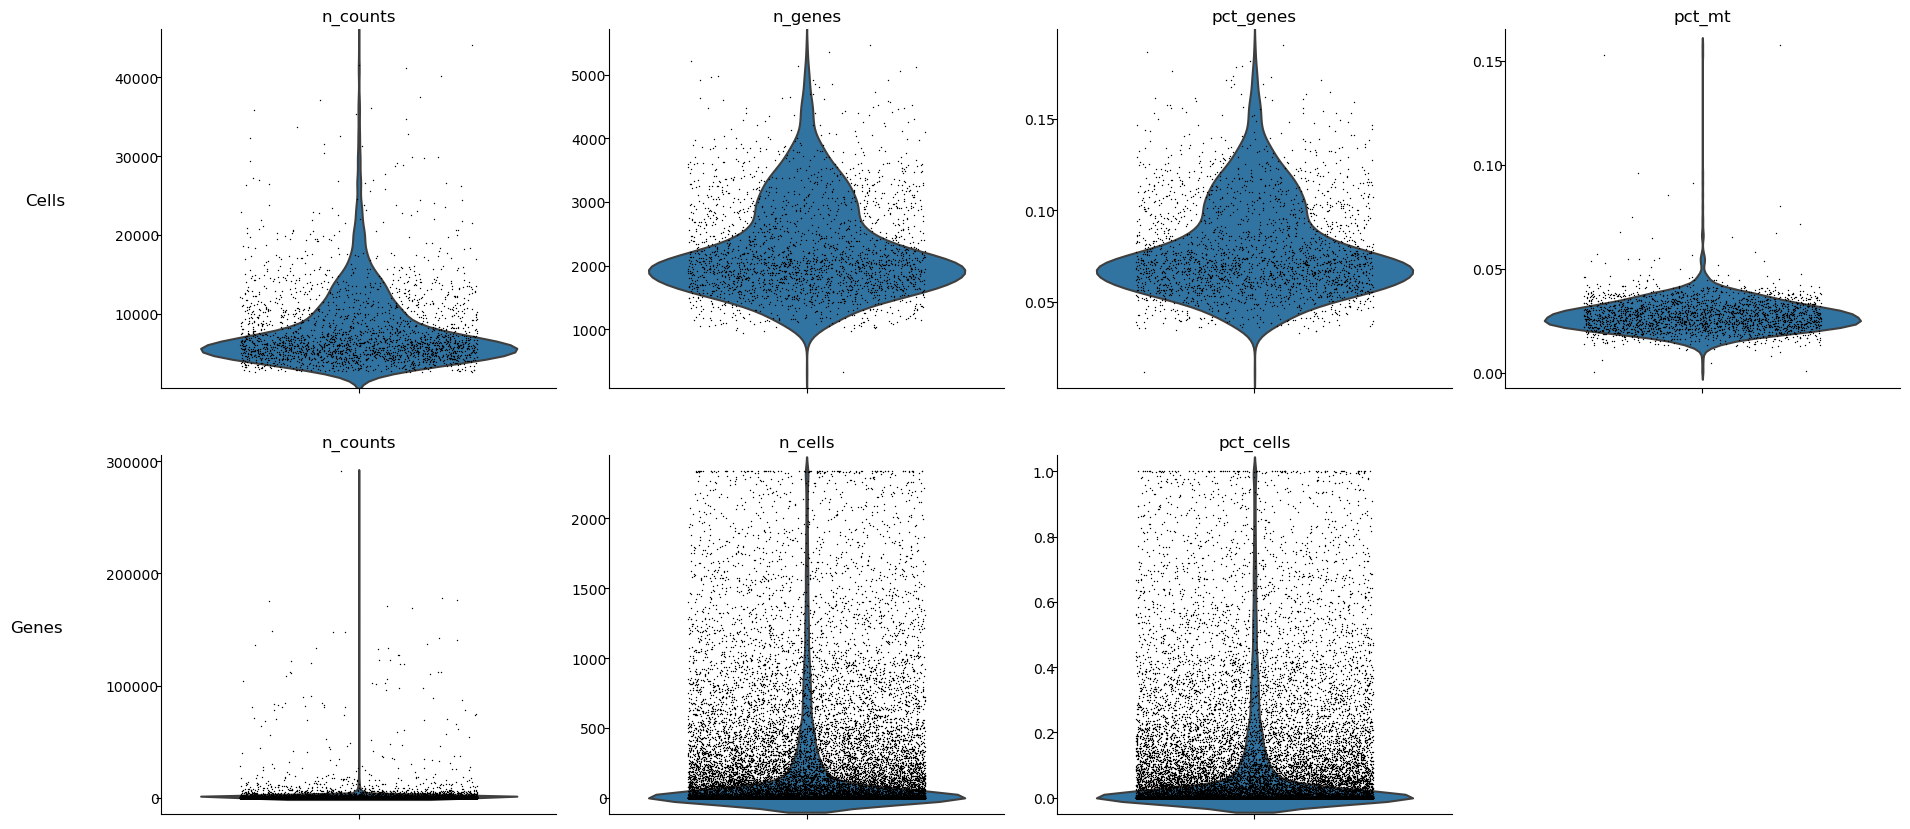

In [64]:
st.plot_qc(adata,jitter=0.3,)

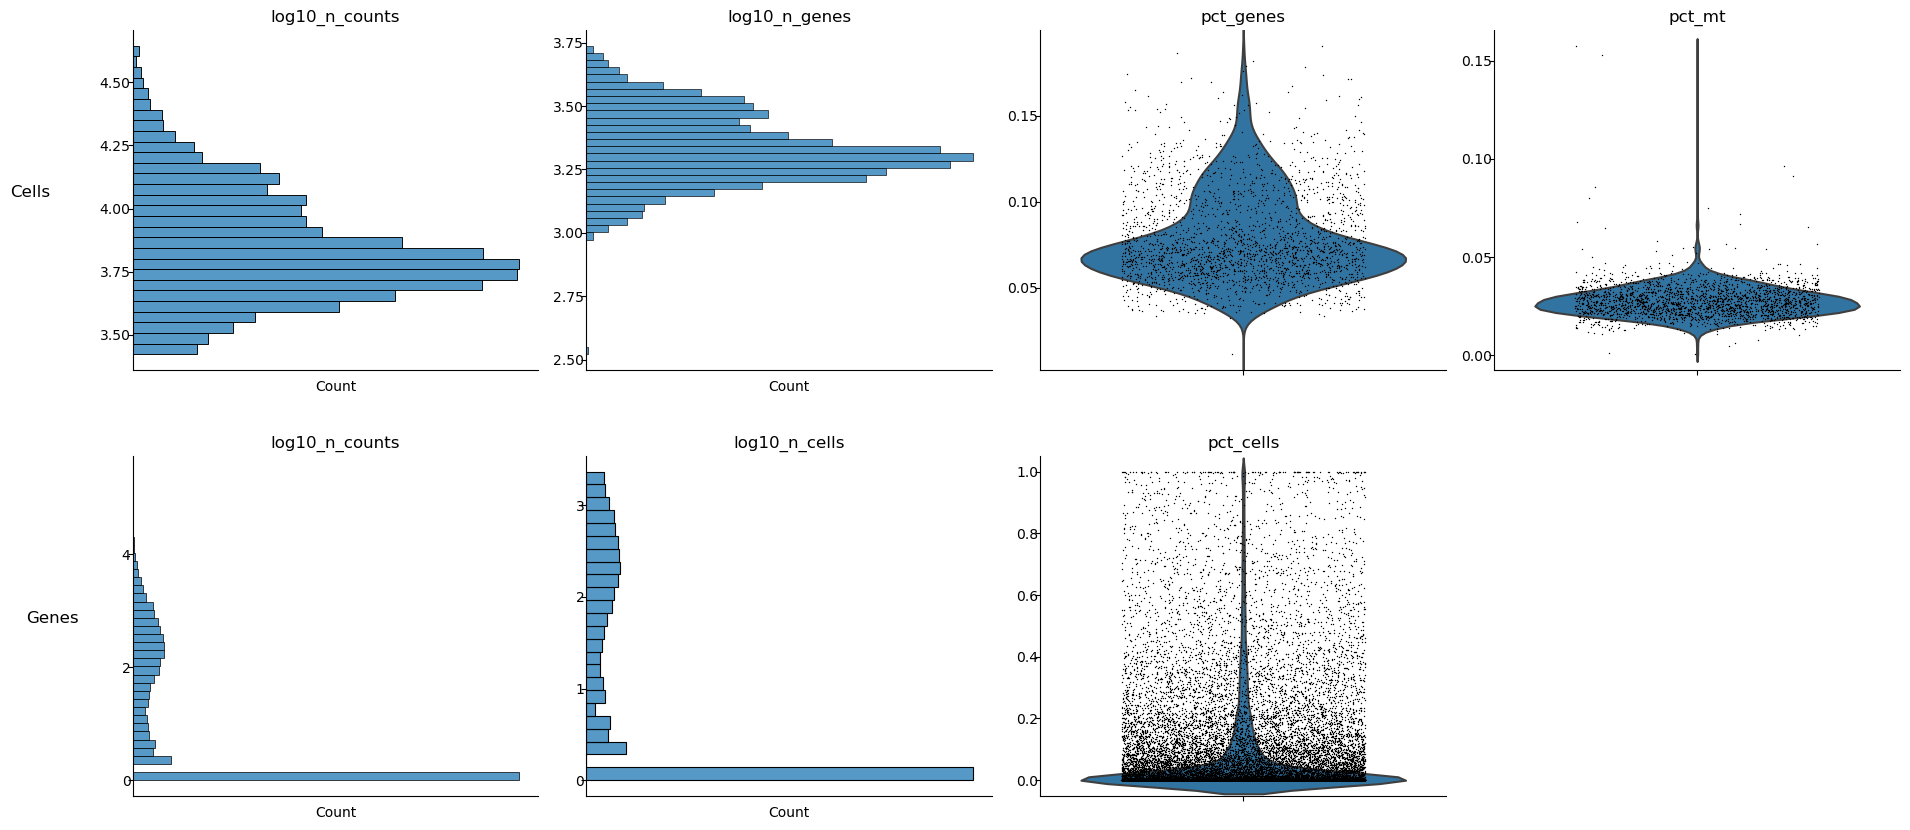

In [65]:
### histogram plots and log-scale are also supported
st.plot_qc(adata,jitter=0.3,log_scale=[0,1,4,5],hist_plot=[0,1,4,5]) 

In [66]:
# From the article
st.filter_cells(adata, min_n_features=200)
st.filter_features(adata, min_n_cells =3)

filter cells based on min_n_features


/home/jasiek/miniconda3/envs/stream/lib/python3.7/site-packages/anndata/core/anndata.py:1239: FutureWarning: is_categorical is deprecated and will be removed in a future version.  Use is_categorical_dtype instead
  if is_categorical(df_full[k]):


after filtering out low-quality cells: 
2337 cells, 28692 genes
Filter genes based on min_n_cells
After filtering out low-expressed genes: 
2337 cells, 14287 genes


In [67]:
###Normalize gene expression based on library size  
st.normalize(adata,method='lib_size')
###Logarithmize gene expression 
st.log_transform(adata)
###Remove mitochondrial genes 
st.remove_mt_genes(adata)

remove mitochondrial genes:
['mt-Nd1', 'mt-Nd2', 'mt-Co1', 'mt-Co2', 'mt-Atp8', 'mt-Atp6', 'mt-Co3', 'mt-Nd3', 'mt-Nd4l', 'mt-Nd4', 'mt-Nd5', 'mt-Nd6', 'mt-Cytb']


### Feature selection

770 variable genes are selected
CPU times: user 2.33 s, sys: 744 ms, total: 3.07 s
Wall time: 5.12 s


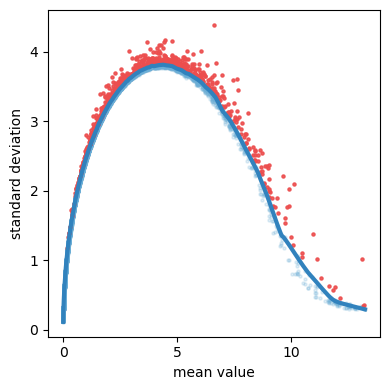

In [46]:
%%time
st.select_variable_genes(adata,loess_frac=0.005) 
# The number of variable genes is set to 1_648 because it was the number of genes kept in the original article's analyses

714 variable genes are selected
CPU times: user 2.03 s, sys: 962 ms, total: 2.99 s
Wall time: 4.77 s


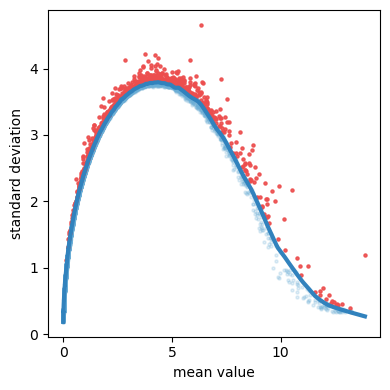

In [68]:
%%time
st.select_variable_genes(adata,loess_frac=0.005) 

In [105]:
marker_genes = pd.Series(list(set(it.chain.from_iterable(states_and_markers.values()))))
len(marker_genes)

NameError: name 'it' is not defined

# SCANPY

In [20]:
for idx in datasetsIds:
    batch_id = "_".join(idx.split("_")[1:3])
    print(batch_id)

young_A
young_B
old_A
old_B


In [21]:
%%time
datasets_adata = []

for idx in datasetsIds:
    batch_id = "_".join(idx.split("_")[1:3])
    adata = sc.read_csv(idx + "merged.tsv", delimiter="\t")
    adata = adata.T
    adata.obs_names_make_unique()
    adata.var_names_make_unique()
    adata.X = adata.X.astype(int)
    adata.obs['batch'] = batch_id
    adata = preprocess_like_herault_data_preparation(adata, copy=True)
    datasets_adata.append(adata)

/home/jan.malinowski/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/anndata/_core/anndata.py:1823: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/home/jan.malinowski/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/anndata/_core/anndata.py:1825: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/jan.malinowski/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/anndata/_core/anndata.py:1823: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/home/jan.malinowski/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/anndata/_core/anndata.py:1825: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/jan.malinowski/anaconda3/envs/sc

CPU times: user 29.8 s, sys: 2.69 s, total: 32.4 s
Wall time: 32.5 s


In [21]:
adata

AnnData object with n_obs × n_vars = 4154 × 28692
    obs: 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'log1p'

In [15]:
datasets_adata[0].obs.head()

,batch,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mt,log1p_total_counts_mt,pct_counts_mt
AAACCTGAGTTCGATC-1,young_A,2054,7.628031,5003,8.517993,31.421147,43.393964,52.668399,66.620028,218,5.389072,4.357386
AAACCTGCAATCGGTT-1,young_A,1884,7.541683,4708,8.457231,34.430756,46.983857,55.819881,70.029737,176,5.176150,3.738318
AAACCTGCACACGCTG-1,young_A,2295,7.738924,5877,8.678972,26.680279,38.506040,48.987579,64.352561,98,4.595120,1.667517
AAACCTGCACGGATAG-1,young_A,2997,8.005701,9279,9.135617,29.076409,41.825628,51.406402,64.166397,387,5.961005,4.170708
AAACCTGCATCATCCC-1,young_A,3329,8.110728,10987,9.304559,30.618003,43.205607,52.361882,64.831164,297,5.697093,2.703195


In [45]:
merged_adata = createMergedDataset(datasetsIds, datasets_adata)

In [23]:
adata.obs['batch'].head()

AAACCTGCATTTGCCC-1    old_B
AAACCTGGTACCCAAT-1    old_B
AAACCTGGTCAAACTC-1    old_B
AAACCTGGTCCGAATT-1    old_B
AAACCTGGTCTTGTCC-1    old_B
Name: batch, dtype: object

In [24]:
adata.var.head()

,mt,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts
Xkr4,False,0,0.000000,0.000000,100.000000,0,0.000000
Gm1992,False,0,0.000000,0.000000,100.000000,0,0.000000
Gm37381,False,1,0.000241,0.000241,99.975927,1,0.693147
Rp1,False,0,0.000000,0.000000,100.000000,0,0.000000
Rp1-1,False,0,0.000000,0.000000,100.000000,0,0.000000


In [28]:
#adata = common_preprocessing(adata)

In [86]:
results = hvg_scanpy(adata, method="seurat")

In [96]:
results.rename(columns={'highly_variable':'test'})

,means,dispersions,dispersions_norm,test,highly_variable_nbatches,highly_variable_intersection
0610007P14Rik,0.380706,-0.774633,-0.542946,False,0,False
0610009B22Rik,0.232553,-0.645925,-0.391664,False,0,False
0610009L18Rik,0.092736,-0.494567,-0.287048,False,0,False
0610009O20Rik,0.118020,-0.499735,-0.222509,False,0,False
0610010F05Rik,0.043499,-0.437640,-0.183848,False,0,False
...,...,...,...,...,...,...
mt-Nd3,0.466429,-0.864650,-0.384540,False,0,False
mt-Nd4,1.095663,-2.383065,-0.991078,False,0,False
mt-Nd4l,0.252010,-0.582584,0.246719,False,1,False
mt-Nd5,0.479608,-0.936861,-0.615138,False,0,False


In [66]:
# From the article
st.filter_cells(adata, min_n_features=200)
st.filter_features(adata, min_n_cells =3)

filter cells based on min_n_features


/home/jasiek/miniconda3/envs/stream/lib/python3.7/site-packages/anndata/core/anndata.py:1239: FutureWarning: is_categorical is deprecated and will be removed in a future version.  Use is_categorical_dtype instead
  if is_categorical(df_full[k]):


after filtering out low-quality cells: 
2337 cells, 28692 genes
Filter genes based on min_n_cells
After filtering out low-expressed genes: 
2337 cells, 14287 genes


In [67]:
###Normalize gene expression based on library size  
st.normalize(adata,method='lib_size')
###Logarithmize gene expression 
st.log_transform(adata)
###Remove mitochondrial genes 
st.remove_mt_genes(adata)

remove mitochondrial genes:
['mt-Nd1', 'mt-Nd2', 'mt-Co1', 'mt-Co2', 'mt-Atp8', 'mt-Atp6', 'mt-Co3', 'mt-Nd3', 'mt-Nd4l', 'mt-Nd4', 'mt-Nd5', 'mt-Nd6', 'mt-Cytb']


In [ ]:
# Teraz Twoja macierz 'adata.obs' zawiera kolumnę 'batch' z wartościami 'young_A' i 'young_B'
print(adata.obs.head())

# 3. Standardowy preprocessing przed HVG
sc.pp.normalize_total(adata, target_sum=1e4)

# 4. KLUCZOWY MOMENT: Selekcja HVG z parametrem batch_key
# Dzięki temu Scanpy wyliczy HVG dla każdej myszy osobno i wybierze te wspólne
# UWAGA: Metoda Pearsona WYMAGA surowych zliczeń (integer counts)
# Nie logarytmuj danych przed tą funkcją!

In [ ]:


# Teraz możesz podejrzeć, które geny zostały wybrane
print(adata.var.head())

In [55]:
print(ad.__version__)

0.12.10


/tmp/ipykernel_7823/3757652304.py:1: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  print(ad.__version__)


In [2]:
adata

NameError: name 'adata' is not defined

### QC v2

In [ ]:
from stream_qc_minimal import cal_qc, plot_qc



In [26]:
cal_qc(adata, assay="rna")

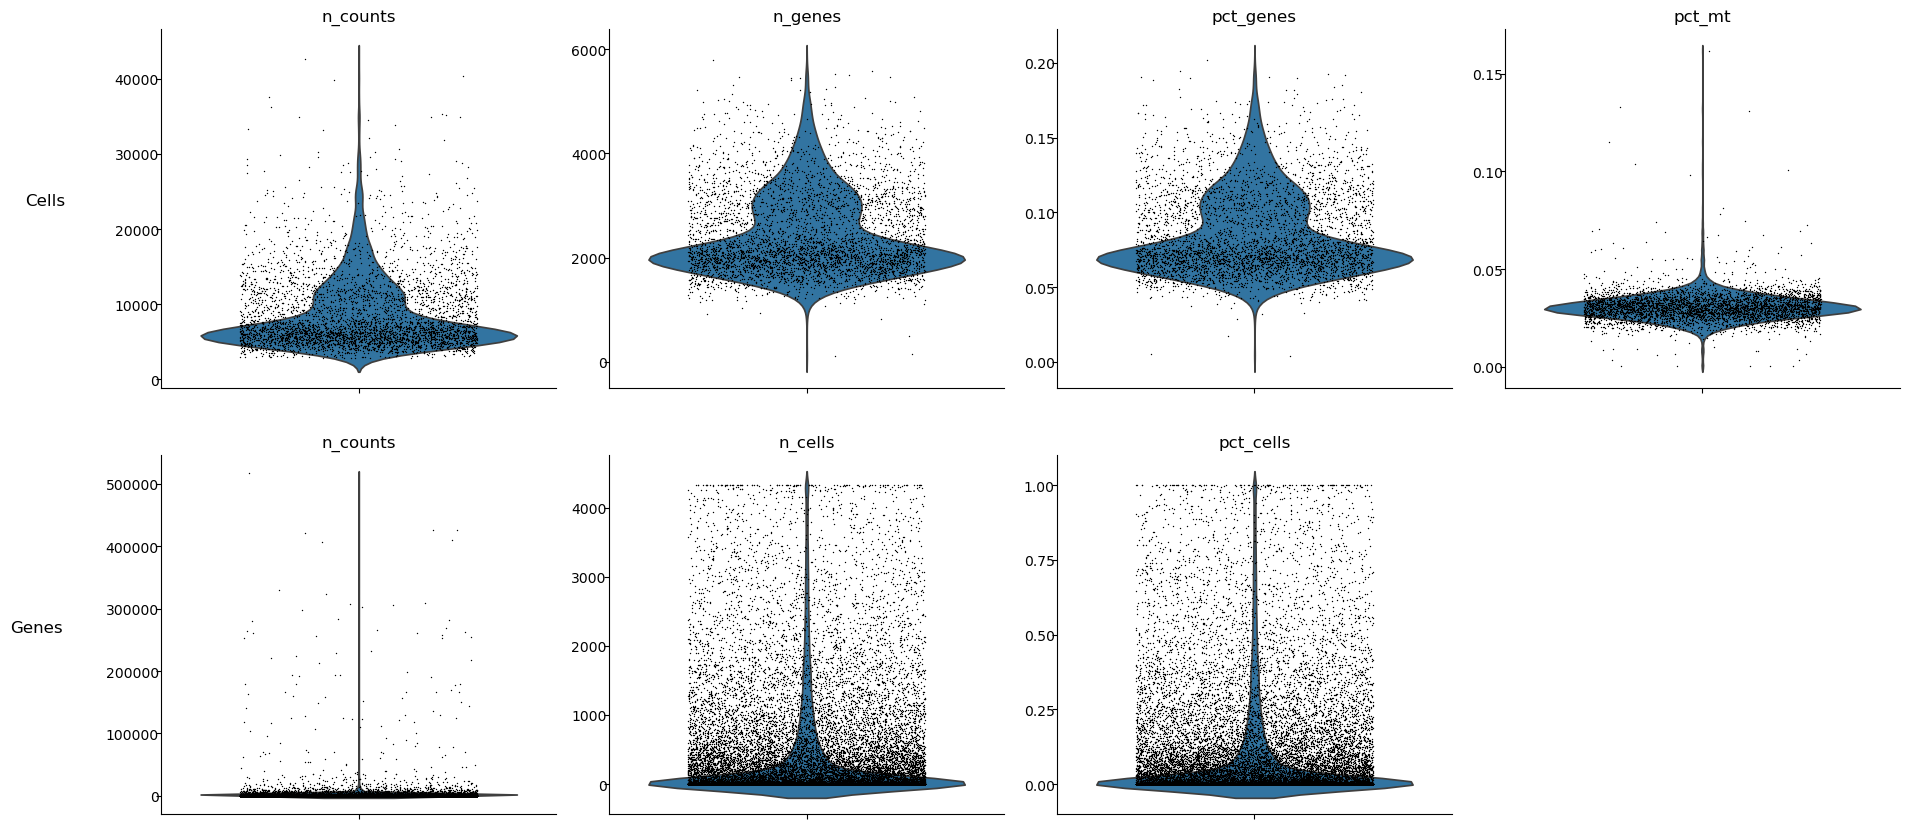

In [27]:
plot_qc(adata, jitter=0.3)


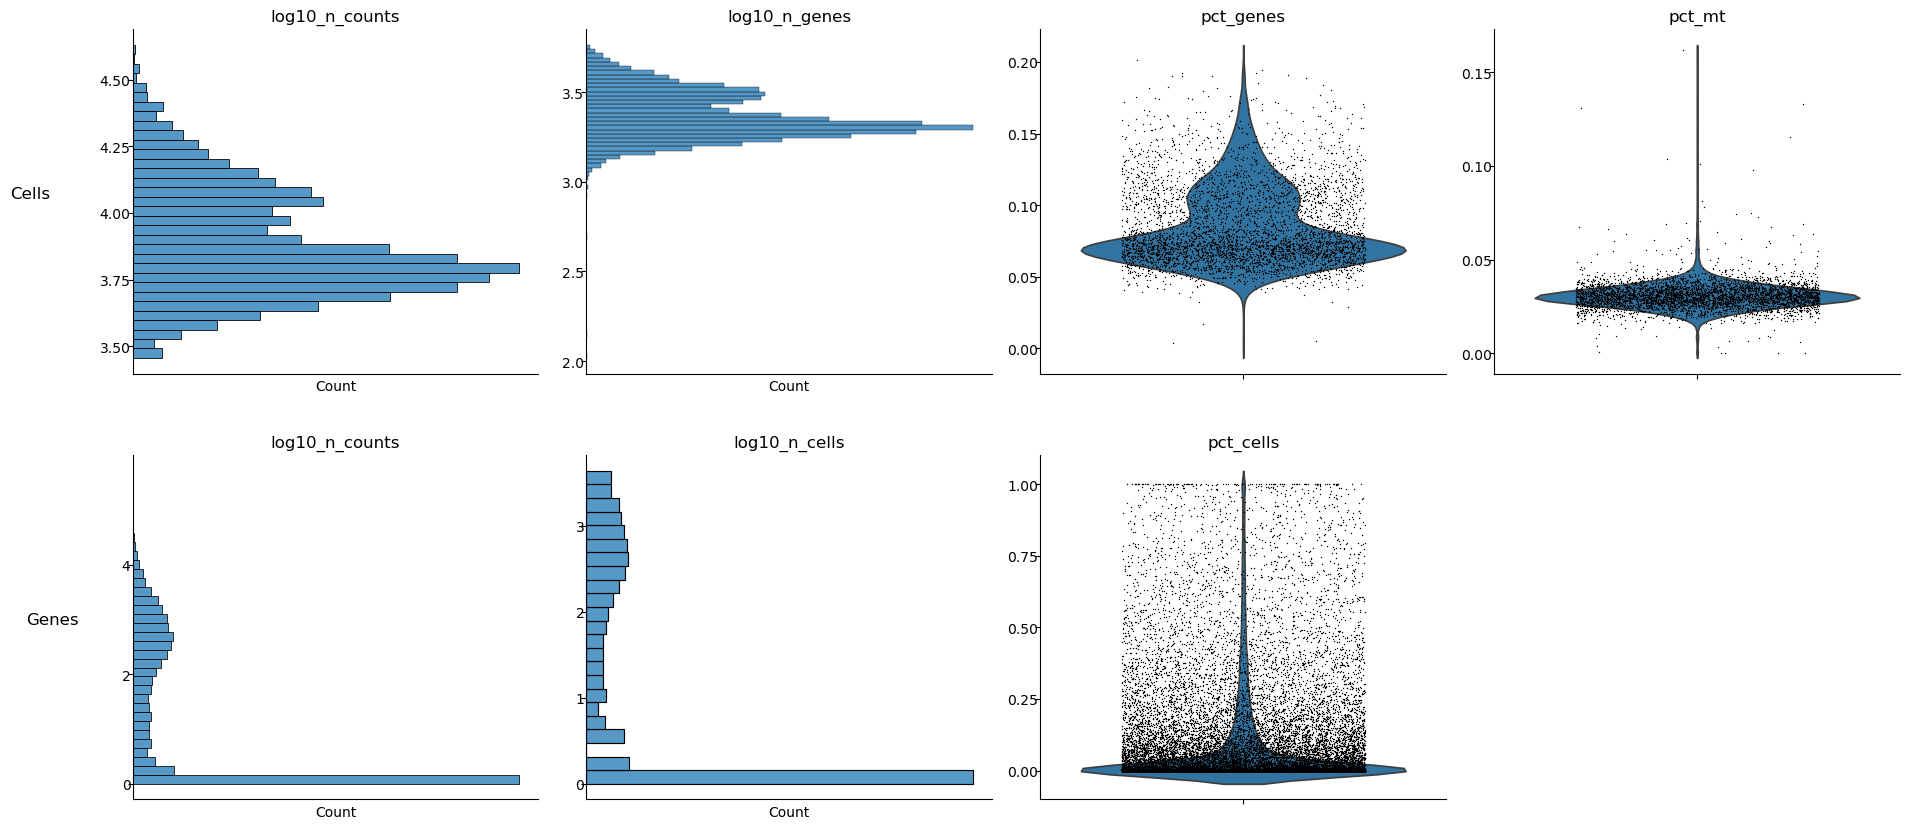

In [28]:
plot_qc(adata, jitter=0.3, log_scale=[0,1,4,5], hist_plot=[0,1,4,5])

In [ ]:
# From the article
adata = adata_original.copy()
# 1. Filtrowanie komórek (min 200 genów)
sc.pp.filter_cells(adata, min_genes=200)

# 2. Filtrowanie genów (min 3 komórki)
sc.pp.filter_genes(adata, min_cells=3)

#print(adata.var_names)

# 3. Usuwanie genów mitochondrialnych
# Najpierw identyfikujemy geny MT (zaczynające się od MT- lub mt-)
adata.var['mt'] = adata.var_names.str.startswith('MT-') # lub 'mt-' dla myszy
# Następnie filtrujemy obiekt, zostawiając tylko te, które NIE są mt
adata = adata[:, ~adata.var['mt']].copy()

# 4. Normalizacja (library size)
# target_sum=None automatycznie skaluje do średniej liczby zliczeń na komórkę

### Clusterization

In [ ]:
# setting highly variable as highly deviant to use scanpy 'use_highly_variable' argument in sc.pp.pca
adata.var["highly_variable"] = adata.var["highly_deviant"]
sc.pp.pca(adata, svd_solver="arpack", mask_var="highly_variable")

In [ ]:
sc.pl.pca_scatter(adata, color="total_counts")

In [60]:
sc.pp.neighbors(merged_adata)
sc.tl.umap(merged_adata)

/home/jan.malinowski/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 28692 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)


KeyboardInterrupt: 

In [ ]:
sc.pl.umap(
    merged_adata,
    color=["total_counts", "pct_counts_mt", "scDblFinder_score", "scDblFinder_class"],
)

### HVG selection

In [88]:
hvg

In [86]:
hvg, method

(None, 'seurat_v3')

In [24]:
hvg_results = []

In [25]:
%%time
for method in {method for method in HVG_METHODS if method != 'consensus'}:
    hvg = hvg_scanpy(merged_adata, method=method)
    hvg.rename(columns={'highly_variable':method}, inplace=True)
    hvg = hvg[method]
    hvg_results.append(hvg)

HERE
seurat_v3
                   means  variances       gene_name  highly_variable_nbatches  \
Xkr4            0.000000   0.000000            Xkr4                         0   
Gm1992          0.000000   0.000000          Gm1992                         0   
Gm37381         0.000201   0.000201         Gm37381                         0   
Rp1             0.000000   0.000000             Rp1                         0   
Rp1-1           0.000000   0.000000           Rp1-1                         0   
...                  ...        ...             ...                       ...   
AC168977.1      0.010526   0.011489      AC168977.1                         1   
PISD            1.012471   1.273279            PISD                         0   
DHRSX           0.253637   0.278898           DHRSX                         0   
Vmn2r122        0.000000   0.000000        Vmn2r122                         0   
CAAA01147332.1  0.007576   0.007519  CAAA01147332.1                         0   

            

In [26]:
eval_results = pd.concat(hvg_results, axis=1)

In [27]:
eval_results

,seurat,seurat_v3,pearson_residuals,seurat_v3_paper,cell_ranger
0610007P14Rik,False,False,False,False,False
0610009B22Rik,False,False,False,False,False
0610009L18Rik,False,False,False,False,True
0610009O20Rik,False,False,False,False,False
0610010F05Rik,False,False,False,False,False
...,...,...,...,...,...
mt-Nd3,False,False,True,False,False
mt-Nd4,False,False,True,False,False
mt-Nd4l,False,False,False,False,True
mt-Nd5,False,False,False,False,True


In [28]:
eval_results['seurat_v3_paper'].sum()

np.int64(2000)

In [29]:
cols = list(eval_results.columns)

In [30]:
results_without_nulls = eval_results[eval_results[cols].any(axis=1)]

In [31]:
true_counts = eval_results[cols].sum(axis=1)

In [32]:
df_filtered = eval_results[true_counts > 1]

In [33]:
result = df_filtered.value_counts(subset=cols).sort_index()

In [34]:
result

seurat  seurat_v3  pearson_residuals  seurat_v3_paper  cell_ranger
False   False      False              True             True           121
                   True               False            True            97
                                      True             False           47
                                                       True            34
        True       False              False            True            29
                                      True             False          347
                                                       True            75
                   True               False            False          144
                                                       True             7
                                      True             False          261
                                                       True            86
True    False      False              False            True            13
                                      True   

/home/jan.malinowski/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/jan.malinowski/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object 

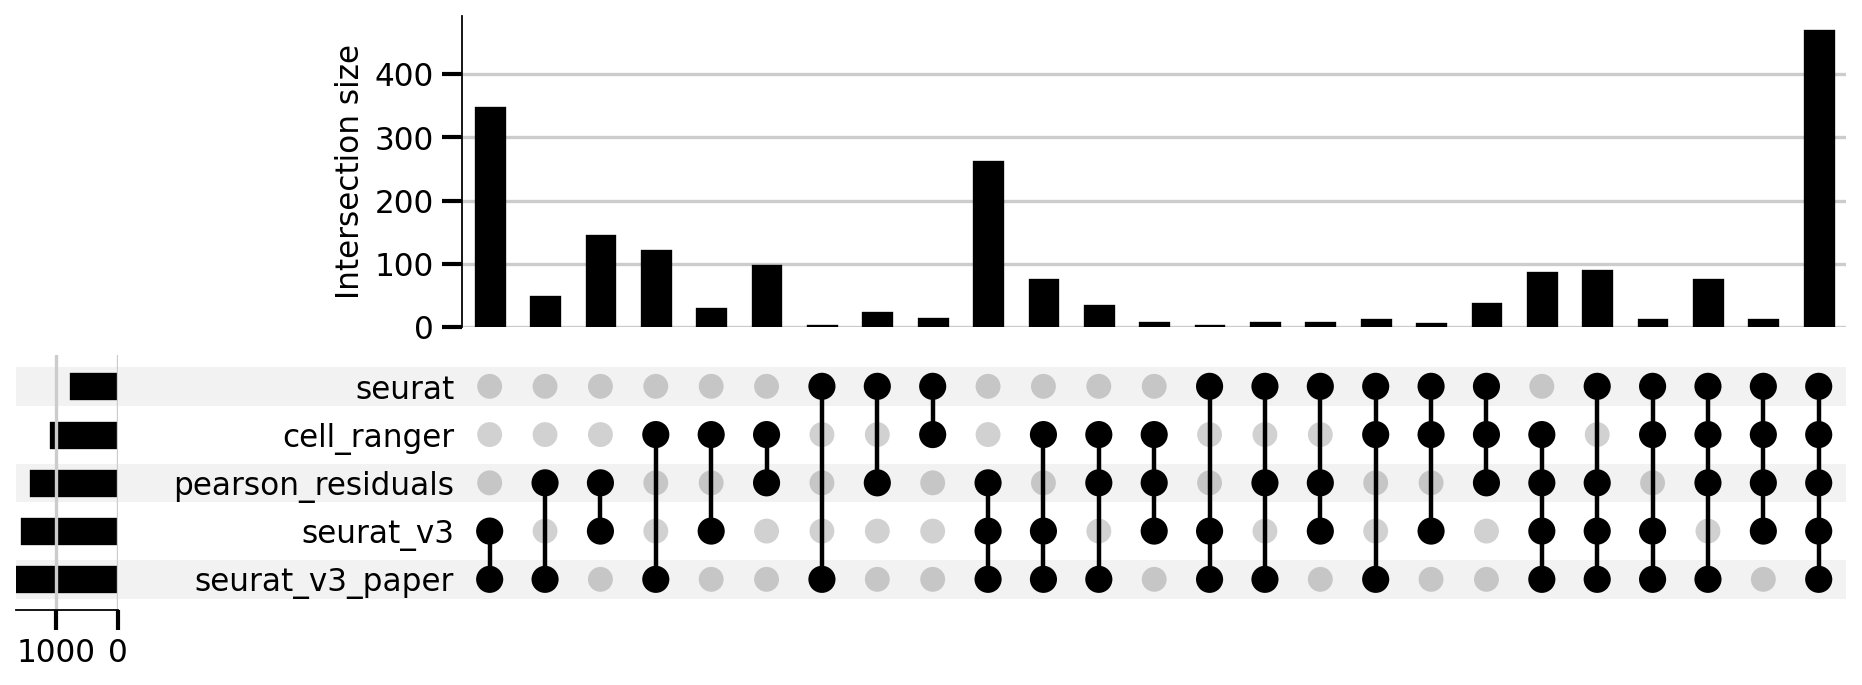

In [35]:
ax_dict = UpSet(result).plot()

In [36]:
hvgs = true_counts[true_counts == 5].index

In [37]:
marker_genes = pd.Series(list(set(it.chain.from_iterable(states_and_markers.values()))))
len(marker_genes)

23

In [38]:
100 * marker_genes.isin(hvgs).mean()

np.float64(47.82608695652174)

In [39]:
marker_genes[~marker_genes.isin(hvgs)]

1      Hoxa9
2       Spi1
3      Zfpm1
4       Tal1
7       Fli1
8      Ikzf1
10       Srf
11      Irf9
13    Zbtb16
15     Kdm5b
17     Foxp1
20    Bclaf1
dtype: object

In [ ]:
export_markers = adata.uns['var_genes'].copy(deep=True)
export_markers = export_markers.append(pd.Index(marker_genes[~marker_genes.isin(adata.uns["var_genes"])]))
export_markers

In [58]:
export_markers = hvgs.append(pd.Index(marker_genes[~marker_genes.isin(hvgs)]))

In [66]:
len(export_markers)

481

In [ ]:
n_batches = adata.var["highly_variable_nbatches"].value_counts()
ax = n_batches.plot(kind="bar")
n_batches

### save hvgs

In [57]:
# extract the genes index
var_genes = adata.uns["var_genes"]
var_genes

KeyError: 'var_genes'

In [ ]:
[f.name for f in _publish_dir.glob("*csv")]

In [ ]:
adata.to_df()[export_markers].to_csv(outfile.as_posix())

In [ ]:
[f.name for f in _publish_dir.glob("*csv")]

In [67]:
adata_hvg = merged_adata[:,export_markers].copy()

In [68]:
normalize_log_scanpy(adata_hvg, target_sum=1e4)


In [69]:
# setting highly variable as highly deviant to use scanpy 'use_highly_variable' argument in sc.pp.pca

In [ ]:
adata.var["highly_variable"] = adata.var["highly_deviant"]

In [70]:
sc.pp.pca(adata_hvg)

In [43]:
sc.pp.pca(merged_adata)

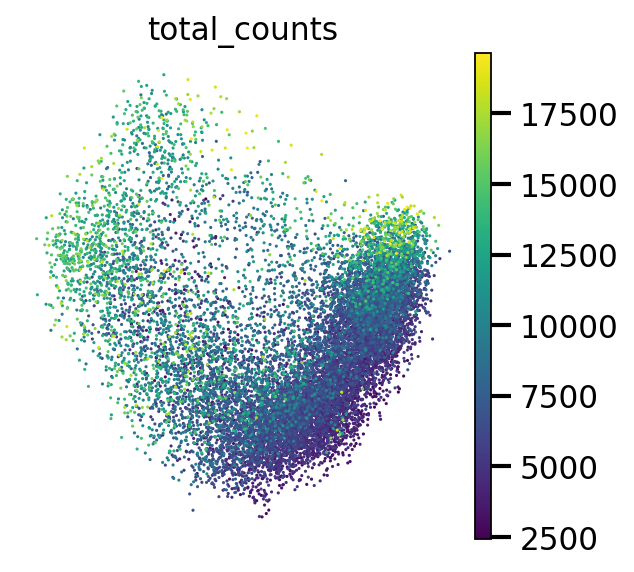

In [71]:
sc.pl.pca_scatter(adata_hvg, color="total_counts")

In [ ]:
sc.pp.highly_variable_genes(adata)

In [ ]:
sc.tl.pca(adata_hvg)
sc.pp.neighbors(adata)
sc.tl.umap(adata)
adata

In [ ]:
adata.uns[batch_key + "_colors"] = [
    "#1b9e77",
    "#d95f02",
    "#7570b3",
]  # Set custom colours for batches
sc.pl.umap(adata, color=[label_key, batch_key], wspace=1)

### Data integration

In [72]:
adata_integrated = adata_hvg.copy()

In [73]:
adata_integrated

AnnData object with n_obs × n_vars = 14915 × 481
    obs: 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'mt'
    uns: 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'

In [74]:
adata_integrated.obs_names

Index(['AAACCTGAGTTCGATC-1_0', 'AAACCTGCAATCGGTT-1_0', 'AAACCTGCACACGCTG-1_0',
       'AAACCTGCACGGATAG-1_0', 'AAACCTGCATCATCCC-1_0', 'AAACCTGCATCTACGA-1_0',
       'AAACCTGCATTCACTT-1_0', 'AAACCTGGTATAGTAG-1_0', 'AAACCTGGTGACTCAT-1_0',
       'AAACCTGGTTACGACT-1_0',
       ...
       'TTTGGTTTCCGTAGGC-1_3', 'TTTGGTTTCGGCTTGG-1_3', 'TTTGTCACAGCTTAAC-1_3',
       'TTTGTCACATTCCTGC-1_3', 'TTTGTCAGTCATGCCG-1_3', 'TTTGTCAGTCTTGTCC-1_3',
       'TTTGTCAGTGGTAACG-1_3', 'TTTGTCATCAACCAAC-1_3', 'TTTGTCATCACAGGCC-1_3',
       'TTTGTCATCAGTACGT-1_3'],
      dtype='object', length=14915)

In [75]:
adata_integrated.obs["batch"]

AAACCTGAGTTCGATC-1_0    young_A
AAACCTGCAATCGGTT-1_0    young_A
AAACCTGCACACGCTG-1_0    young_A
AAACCTGCACGGATAG-1_0    young_A
AAACCTGCATCATCCC-1_0    young_A
                         ...   
TTTGTCAGTCTTGTCC-1_3      old_B
TTTGTCAGTGGTAACG-1_3      old_B
TTTGTCATCAACCAAC-1_3      old_B
TTTGTCATCACAGGCC-1_3      old_B
TTTGTCATCAGTACGT-1_3      old_B
Name: batch, Length: 14915, dtype: category
Categories (4, object): ['old_A', 'old_B', 'young_A', 'young_B']

In [76]:
adata_integrated.obs["batch"] = adata_integrated.obs["batch"].astype("category")


In [77]:
%%time
scib.ig.scanorama(adata_integrated, batch="batch", hvg=list(export_markers))

Found 481 genes among all datasets
[[0.         0.73928743 0.47292349 0.13057041]
 [0.         0.         0.21160146 0.47727273]
 [0.         0.         0.         0.87878788]
 [0.         0.         0.         0.        ]]
Processing datasets (2, 3)
Processing datasets (0, 1)
Processing datasets (1, 3)
Processing datasets (0, 2)
Processing datasets (1, 2)
Processing datasets (0, 3)
CPU times: user 1min 55s, sys: 4.37 s, total: 1min 59s
Wall time: 15.7 s


/home/jan.malinowski/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/scib/utils.py:72: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  return anndata.AnnData.concatenate(*adata_list, **kwargs)


AnnData object with n_obs × n_vars = 14915 × 481
    obs: 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'mt'
    obsm: 'X_pca', 'X_scanorama', 'X_emb'

In [78]:
adata_integrated

AnnData object with n_obs × n_vars = 14915 × 481
    obs: 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'mt'
    uns: 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'

In [79]:
sc.pp.neighbors(adata_integrated)

In [80]:
sc.tl.umap(adata_integrated)

In [81]:
adata_integrated

AnnData object with n_obs × n_vars = 14915 × 481
    obs: 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'mt'
    uns: 'log1p', 'pca', 'neighbors', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [82]:
batch_key = "batch"

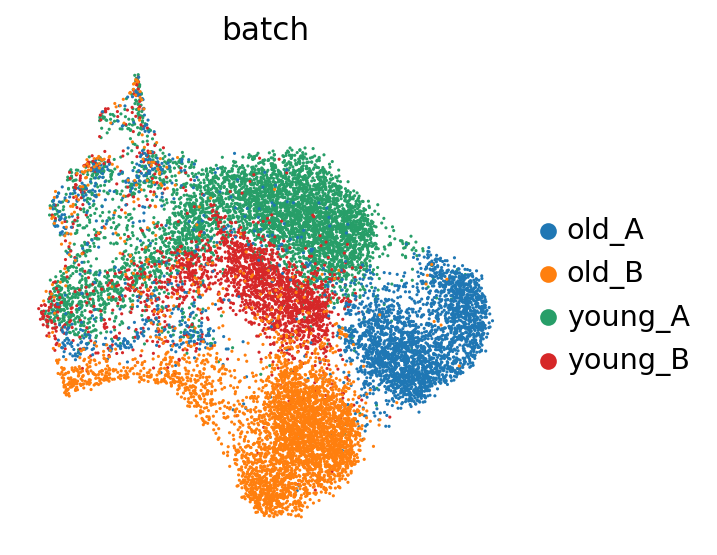

In [83]:
sc.pl.umap(adata_integrated, color=[batch_key], wspace=1)

In [105]:
metrics_hvg = scib.metrics.metrics_fast(merged_adata, adata_hvg, batch_key)

TypeError: metrics_fast() missing 1 required positional argument: 'label_key'

In [ ]:
metrics_scanorama = scib.metrics.metrics_fast(merged_adata, adata_integrated, batch_key)

In [84]:
adata_hvg.to_df().to_csv("dataset_hvgs.csv")